```markdown
# ¿Qué factores impulsan las cancelaciones en el sector hotelero?

Este análisis nace de la necesidad de entender a fondo el comportamiento de nuestros huéspedes y la demanda real en nuestros alojamientos. En el mundo de la hotelería (*Hospitality Analytics*), una reserva no es solo un registro; es una promesa de servicio y un espacio reservado que, si se cancela a última hora o se convierte en un *No-Show*, afecta directamente nuestra rentabilidad.

### Lo que buscamos resolver:
1. **El impacto real de las cancelaciones:** Identificar patrones claros analizando la anticipación con la que se reserva (*lead time*) y el rol de las políticas de depósito.
2. **Métricas con sentido de negocio:** Calcular el **ADR** (Tarifa Promedio Diaria) de forma correcta, cuidando de no desvirtuar el análisis con suposiciones de inventario que el dataset no tiene.
3. **Optimización de canales:** Analizar qué segmentos de mercado traen visitas de mayor valor y menor riesgo.
4. **Decisiones basadas en datos:** Construir un reporte final limpio y listo para usar en tableros de control o presentaciones de negocio.
```

```markdown
### 1. Primer vistazo a los datos
Antes de sacar conclusiones, necesitamos conocer el terreno. Vamos a cargar la información y revisar la estructura general de las reservas para entender con qué tipo de datos estamos trabajando.
```

In [34]:
#importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [35]:
df = pd.read_csv('/content/hotel_bookings.csv')

```markdown
### 1.1 Auditoría de Calidad: Limpiando la casa antes de empezar
Para que un análisis sea confiable, los datos deben ser impecables. En esta fase revisamos tres frentes críticos:
* **Duplicados:** Registros idénticos que pueden inflar artificialmente las estadísticas.
* **Datos faltantes:** Identificar nulos y solucionarlos de forma lógica (por ejemplo, no tiene sentido ponerle un promedio a un identificador de agencia o compañía; es mejor etiquetarlos como 'Sin Agente').
* **Anomalías en tarifas (ADR):** Buscar errores de registro, como tarifas negativas o valores absurdamente altos fuera de la realidad.
```

In [46]:
# 1. Identificar Duplicados
duplicados_totales = df.duplicated().sum()
print(f"Filas duplicadas exactas detectadas: {duplicados_totales} ({duplicados_totales / len(df) * 100:.2f}% del dataset)")

# Creamos una versión alternativa del dataset sin duplicados para comparación futura
df_sin_duplicados = df.drop_duplicates()

# 2. Análisis de Valores Faltantes
valores_nulos = df.isnull().sum()
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
calidad_nulos = pd.DataFrame({'Nulos': valores_nulos, 'Porcentaje (%)': porcentaje_nulos})
print("\n--- Análisis de Valores Nulos ---")
display(calidad_nulos[calidad_nulos['Nulos'] > 0])

# Tratamiento de nulos de forma correcta (sin imputar medias a identificadores)
df['agent'] = df['agent'].fillna('Sin Agente')
df['company'] = df['company'].fillna('Sin Compañía')
df['country'] = df['country'].fillna('Desconocido')
df['children'] = df['children'].fillna(0)

# 3. Análisis de Anomalías en Tarifas (ADR)
adr_negativo = df[df['adr'] < 0]
adr_cero = df[df['adr'] == 0]
adr_extremo = df[df['adr'] > 5000]

print("\n--- Análisis de Anomalías en ADR ---")
print(f"Registros con ADR negativo: {len(adr_negativo)}")
print(f"Registros con ADR igual a cero: {len(adr_cero)}")
print(f"Registros con ADR extremo (> $5000): {len(adr_extremo)}")

Filas duplicadas exactas detectadas: 31994 (26.80% del dataset)

--- Análisis de Valores Nulos ---


,Nulos,Porcentaje (%)
children,4,0.003350
country,488,0.408744
agent,16340,13.686238
company,112593,94.306893



--- Análisis de Anomalías en ADR ---
Registros con ADR negativo: 1
Registros con ADR igual a cero: 1959
Registros con ADR extremo (> $5000): 1


```markdown
### 1.2 ¿Por qué es un error trabajar con datos duplicados?
Aquí podemos ver la diferencia real: si dejamos los datos duplicados, la tasa de cancelación parece del **37.04%**. Al limpiarlos y quedarnos con registros únicos, baja al **27.49%**.

Usar el dataset original nos habría llevado a tomar decisiones operativas basadas en un escenario de riesgo mucho más grave del que realmente existe.
```

In [47]:
tasa_con_duplicados = df['is_canceled'].mean() * 100
tasa_sin_duplicados = df_sin_duplicados['is_canceled'].mean() * 100

print(f"Tasa de Cancelación + No-Show (Con Duplicados - Original): {tasa_con_duplicados:.2f}%")
print(f"Tasa de Cancelación + No-Show (Sin Duplicados): {tasa_sin_duplicados:.2f}%")

Tasa de Cancelación + No-Show (Con Duplicados - Original): 37.04%
Tasa de Cancelación + No-Show (Sin Duplicados): 27.49%


```markdown
### 1.3 Entendiendo el comportamiento: Cancelaciones vs. No-Shows
En el día a día de un hotel, no es lo mismo recibir una cancelación con semanas de anticipación (lo que nos da margen para revender la habitación) que un cliente que simplemente no se presenta el día del check-in (*No-Show*). Vamos a separar estos dos mundos.
```

--- Desglose de Estados de Reserva (Dataset Original) ---


,Reservas,Porcentaje (%)
reservation_status,,
Check-Out,75166,62.958372
Canceled,43017,36.030656
No-Show,1207,1.010972


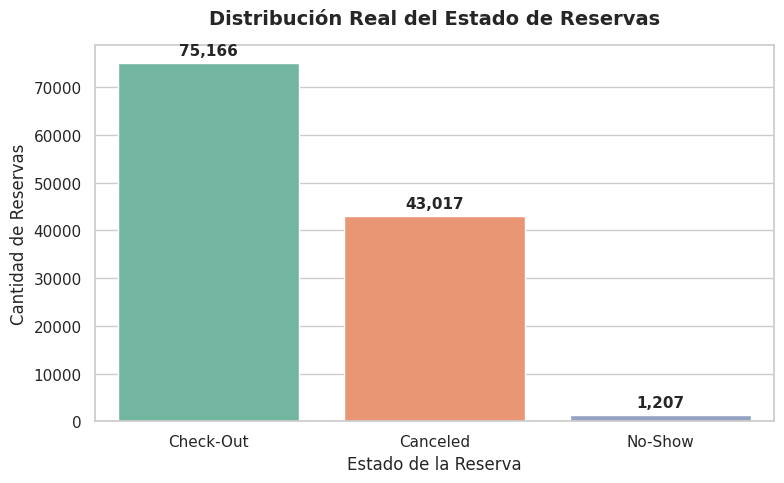

In [49]:
# 1. Calcular frecuencias absolutas y relativas del estado de las reservas
status_counts = df['reservation_status'].value_counts()
status_percentages = df['reservation_status'].value_counts(normalize=True) * 100

status_summary = pd.DataFrame({
    'Reservas': status_counts,
    'Porcentaje (%)': status_percentages
})

print("--- Desglose de Estados de Reserva (Dataset Original) ---")
display(status_summary)

# 2. Graficar la distribución de los estados
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=status_summary.index, y='Reservas', data=status_summary, palette='Set2', hue=status_summary.index, legend=False)

plt.title('Distribución Real del Estado de Reservas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estado de la Reserva', fontsize=12)
plt.ylabel('Cantidad de Reservas', fontsize=12)

# Añadir los valores en la parte superior de cada barra
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [36]:
# Información general del DataFrame
print("--- Información General del Dataset ---")
df.info()

# Verificar valores nulos por columna
print("\n--- Valores Nulos por Columna ---")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

--- Información General del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390

,0
children,4
country,488
agent,16340
company,112593


```markdown
### 2. Exploración rápida de variables
Echemos un vistazo rápido a los promedios, valores mínimos y máximos de las columnas para asegurarnos de que todo tenga coherencia lógica.
```

In [37]:
# Resumen estadístico de variables numéricas
print("Resumen de variables numéricas:")
display(df.describe().T)

# Resumen de variables categóricas
print("\nResumen de variables categóricas:")
display(df.describe(include=['object']).T)

Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0



Resumen de variables categóricas:


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


```markdown
### 3. Comparativa de cancelaciones por tipo de hotel
¿Se cancela más en la ciudad o en los hoteles de playa? Evaluamos los porcentajes de reservas que no llegaron a concretarse en cada categoría.
```

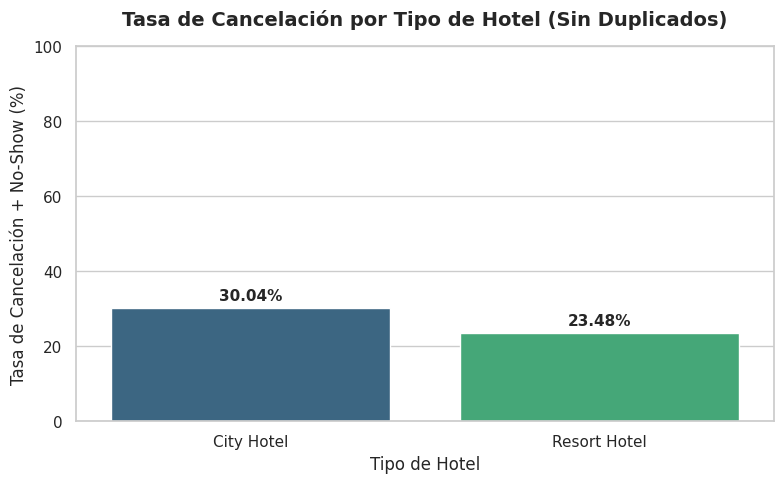

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la tasa de cancelación sobre el dataset sin duplicados
cancellation_rates = df_sin_duplicados.groupby('hotel')['is_canceled'].mean().reset_index()
cancellation_rates['is_canceled'] = cancellation_rates['is_canceled'] * 100

# Crear el gráfico de barras
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='hotel', y='is_canceled', data=cancellation_rates, palette='viridis', hue='hotel', legend=False)

# Personalizar el gráfico
plt.title('Tasa de Cancelación por Tipo de Hotel (Sin Duplicados)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tipo de Hotel', fontsize=12)
plt.ylabel('Tasa de Cancelación + No-Show (%)', fontsize=12)
plt.ylim(0, 100)

# Añadir etiquetas de porcentaje sobre cada barra
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

```markdown
### 4. ¿La anticipación y el tipo de depósito influyen en el comportamiento del cliente?
Intuitivamente, pensamos que una reserva hecha con mucha anticipación corre más riesgo de cancelarse porque los planes de la gente cambian. De igual manera, las políticas de depósito deberían actuar como un freno o un incentivo. Vamos a contrastar estas ideas con los números.
```

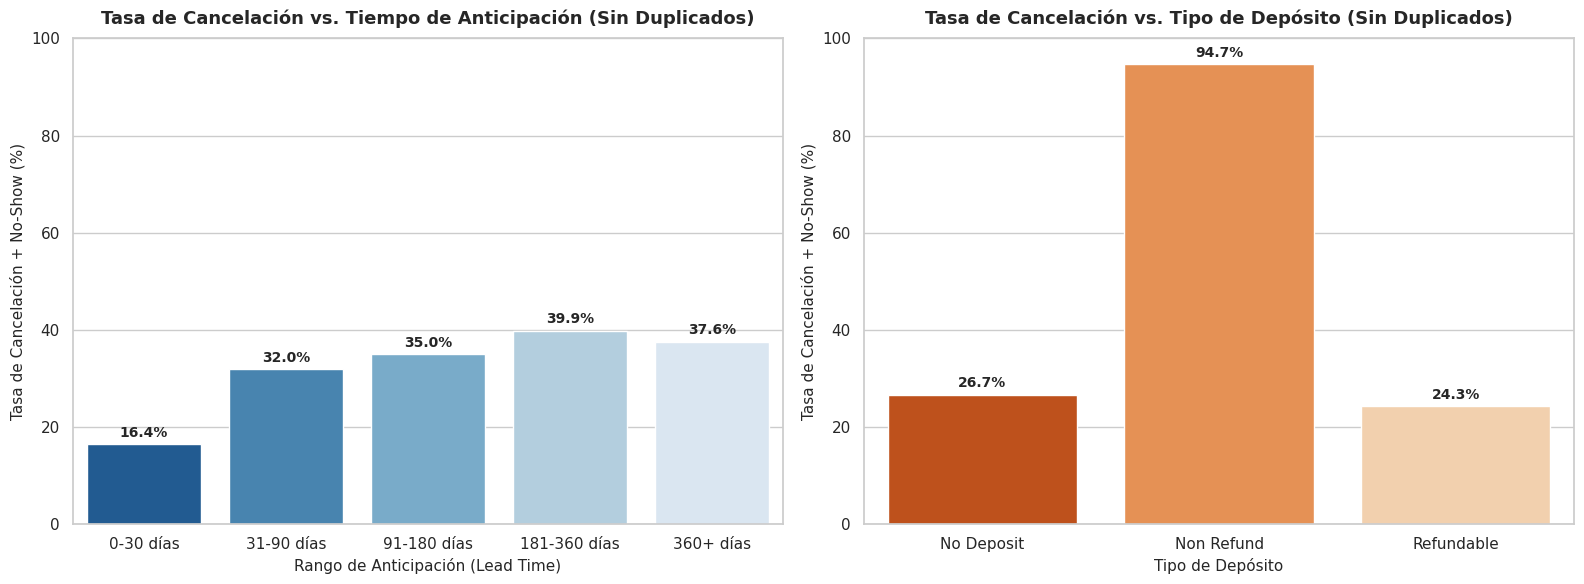

In [51]:
# 1. Crear rangos para Lead Time en el dataset sin duplicados
bins = [0, 30, 90, 180, 360, df_sin_duplicados['lead_time'].max()]
labels = ['0-30 días', '31-90 días', '91-180 días', '181-360 días', '360+ días']
# Usamos loc para evitar advertencias de SettingWithCopy
df_sin_duplicados = df_sin_duplicados.copy()
df_sin_duplicados['lead_time_range'] = pd.cut(df_sin_duplicados['lead_time'], bins=bins, labels=labels, include_lowest=True)

# Calcular tasa de cancelación por rango de anticipación
lead_time_cancel = df_sin_duplicados.groupby('lead_time_range', observed=False)['is_canceled'].mean().reset_index()
lead_time_cancel['is_canceled'] *= 100

# Calcular tasa de cancelación por tipo de depósito
deposit_cancel = df_sin_duplicados.groupby('deposit_type')['is_canceled'].mean().reset_index()
deposit_cancel['is_canceled'] *= 100

# Configurar la figura para mostrar ambos gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Gráfico 1: Cancelación por Lead Time
sns.barplot(ax=axes[0], x='lead_time_range', y='is_canceled', data=lead_time_cancel, palette='Blues_r', hue='lead_time_range', legend=False)
axes[0].set_title('Tasa de Cancelación vs. Tiempo de Anticipación (Sin Duplicados)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Rango de Anticipación (Lead Time)', fontsize=11)
axes[0].set_ylabel('Tasa de Cancelación + No-Show (%)', fontsize=11)
axes[0].set_ylim(0, 100)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=10, fontweight='bold')

# Gráfico 2: Cancelación por Tipo de Depósito
sns.barplot(ax=axes[1], x='deposit_type', y='is_canceled', data=deposit_cancel, palette='Oranges_r', hue='deposit_type', legend=False)
axes[1].set_title('Tasa de Cancelación vs. Tipo de Depósito (Sin Duplicados)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Tipo de Depósito', fontsize=11)
axes[1].set_ylabel('Tasa de Cancelación + No-Show (%)', fontsize=11)
axes[1].set_ylim(0, 100)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

```markdown
### 5. Monitoreo mensual de reservas exitosas
Para ver la salud comercial de los hoteles a lo largo del tiempo, medimos la **Proporción de Reservas No Canceladas** (el porcentaje de transacciones que sí llegaron a buen término).

*Nota de rigor hotelero:* Como no contamos con el inventario físico total de habitaciones del hotel para cada día, evitamos calcular la ocupación tradicional o el RevPAR para no generar reportes engañosos. Nos enfocamos estrictamente en el éxito de la reserva y en el comportamiento del ADR.
```

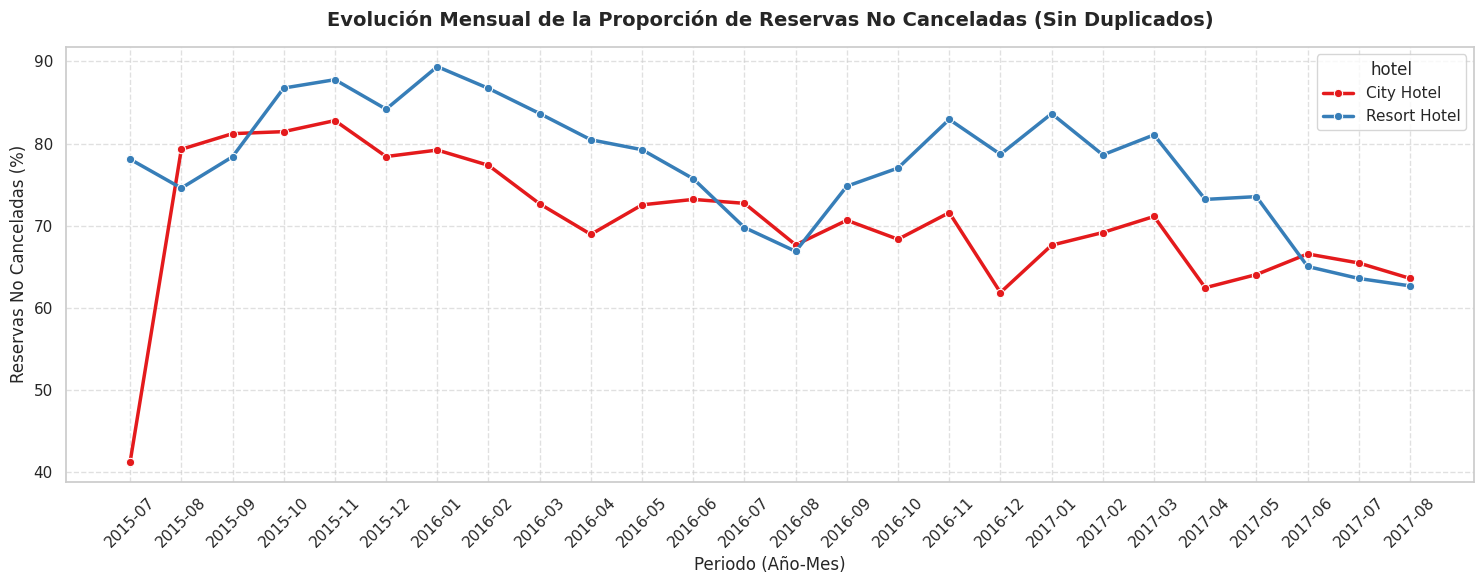

In [52]:
# Mapear los nombres de los meses a números para ordenar cronológicamente
months_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df_sin_duplicados['arrival_date_month_num'] = df_sin_duplicados['arrival_date_month'].map(months_map)

# Agrupar datos por año, mes y tipo de hotel en dataset limpio
kpi_data = df_sin_duplicados.groupby(['arrival_date_year', 'arrival_date_month_num', 'arrival_date_month', 'hotel']).agg(
    total_bookings=('is_canceled', 'count'),
    successful_bookings=('is_canceled', lambda x: (x == 0).sum()),
    average_adr=('adr', 'mean')
).reset_index()

# Calcular la Proporción de Reservas No Canceladas
kpi_data['prop_no_canceladas'] = (kpi_data['successful_bookings'] / kpi_data['total_bookings']) * 100

# Ordenar cronológicamente
kpi_data = kpi_data.sort_values(by=['arrival_date_year', 'arrival_date_month_num'])
kpi_data['date'] = kpi_data['arrival_date_year'].astype(str) + '-' + kpi_data['arrival_date_month_num'].astype(str).str.zfill(2)

# Graficar la evolución de la Proporción de Reservas No Canceladas
plt.figure(figsize=(15, 6))
sns.lineplot(data=kpi_data, x='date', y='prop_no_canceladas', hue='hotel', marker='o', linewidth=2.5, palette='Set1')
plt.title('Evolución Mensual de la Proporción de Reservas No Canceladas (Sin Duplicados)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Reservas No Canceladas (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

```markdown
### 6. Rendimiento y rentabilidad por segmento de mercado
Analizar los canales de venta nos ayuda a saber dónde están los clientes más leales o más rentables. Cruzamos la tasa de conversión (cuántas reservas no se cancelan) con la tarifa promedio (ADR) que paga cada segmento.
```

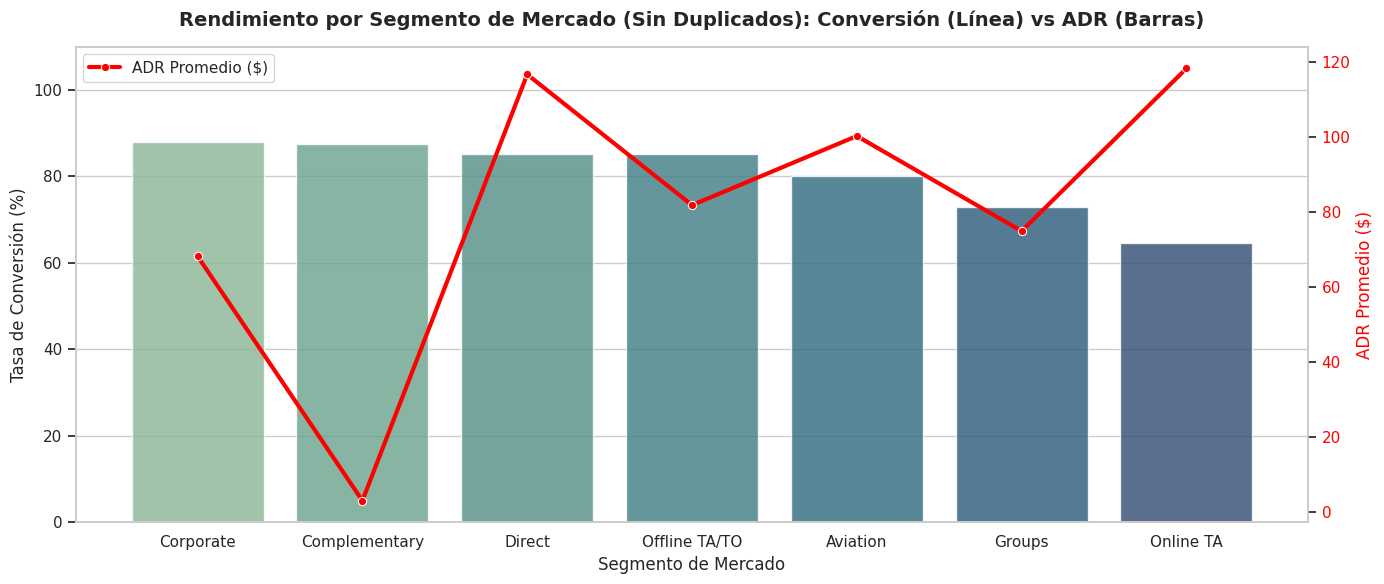

In [53]:
# Calcular métricas clave por segmento de mercado con el dataset sin duplicados
segment_analysis = df_sin_duplicados.groupby('market_segment').agg(
    total_bookings=('is_canceled', 'count'),
    cancellation_rate=('is_canceled', 'mean'),
    average_adr=('adr', 'mean')
).reset_index()

# Convertir tasa de cancelación a porcentaje
segment_analysis['cancellation_rate'] *= 100
# Calcular tasa de conversión (reservas exitosas)
segment_analysis['conversion_rate'] = 100 - segment_analysis['cancellation_rate']

# Filtrar segmentos poco representativos
segment_analysis = segment_analysis[segment_analysis['total_bookings'] > 100].sort_values(by='conversion_rate', ascending=False)

# Graficar la Tasa de Conversión y el ADR promedio por Segmento de Mercado
fig, ax1 = plt.subplots(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# Barras de Tasa de Conversión
sns.barplot(ax=ax1, x='market_segment', y='conversion_rate', data=segment_analysis, palette='crest', hue='market_segment', legend=False, alpha=0.8)
ax1.set_title('Rendimiento por Segmento de Mercado (Sin Duplicados): Conversión (Línea) vs ADR (Barras)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Segmento de Mercado', fontsize=12)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=12)
ax1.set_ylim(0, 110)

# Línea para el ADR Promedio
ax2 = ax1.twinx()
sns.lineplot(ax=ax2, x='market_segment', y='average_adr', data=segment_analysis, color='red', marker='o', linewidth=3, label='ADR Promedio ($)')
ax2.set_ylabel('ADR Promedio ($)', fontsize=12, color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.grid(False)

plt.tight_layout()
plt.show()

```markdown
### 7. Resumen de Hallazgos (Perspectiva de Negocio)

Tras limpiar y analizar a fondo los datos de reservas, estas son las conclusiones clave que debemos considerar para la toma de decisiones:

* **Cuidado con los años parciales (Estacionalidad):**
  * No compares los totales de ventas de 2015, 2016 y 2017 directamente. El dataset solo tiene datos de **julio de 2015 a agosto de 2017**, por lo que el primer y el último año están incompletos. Cualquier comparación anual directa nos dará una idea falsa de caída o crecimiento.

* **1. El riesgo según el tipo de viaje:**
  * El **City Hotel** experimenta una tasa de cancelación significativamente mayor (**30.04%**) en comparación con el **Resort Hotel** (**23.48%**). El cliente urbano suele tener alternativas más a la mano o viajes más dinámicos, lo que amerita políticas de confirmación un poco más estrictas.

* **2. El factor tiempo (Lead Time):**
  * Las reservas hechas a última hora (0-30 días) son sumamente estables (tasa de cancelación del **16.4%**). Sin embargo, cuando los clientes reservan con más de un año de anticipación, las cancelaciones rozan el **37.6%**.
  * *Sugerencia:* No bloquees inventario valioso a tan largo plazo sin asegurar un depósito inicial.

* **3. El enigma de las tarifas "Non-Refund":**
  * Un dato sumamente llamativo es que la gran mayoría de las reservas con tarifa no reembolsable registran cancelaciones. Esto suele ser una alerta de comportamiento atípico (compras masivas de agencias que luego cancelan, posibles fraudes con tarjetas o errores de registro). Debe investigarse a fondo internamente.

* **4. Claridad en los números (No-Shows):**
  * De las reservas totales analizadas, **75,166** terminaron en check-out, **43,017** fueron canceladas previamente y **1,207** se clasificaron como No-Show. Monitorear ese pequeño porcentaje de No-Shows de manera independiente ayuda a optimizar las decisiones de sobreventa de habitaciones.
```

```markdown
### 8. Creación del reporte unificado para BI
Para facilitar la integración de estos resultados con herramientas como Power BI, Tableau o Excel, consolidamos las métricas clave en una sola tabla organizada por dimensiones y la exportamos a un archivo limpio sin duplicados.
```

In [56]:
import pandas as pd

# 1. Preparar dataframes parciales etiquetados para consolidar en un reporte limpio sin duplicados
report_hotel = cancellation_rates.copy().rename(columns={'hotel': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_hotel['Categoría_Dimensión'] = 'Tipo de Hotel'

report_lead = lead_time_cancel.copy().rename(columns={'lead_time_range': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_lead['Categoría_Dimensión'] = 'Rango de Anticipación'
report_lead['Dimensión'] = report_lead['Dimensión'].astype(str)

report_deposit = deposit_cancel.copy().rename(columns={'deposit_type': 'Dimensión', 'is_canceled': 'Tasa_Cancelacion_Pct'})
report_deposit['Categoría_Dimensión'] = 'Tipo de Depósito'

report_segment = segment_analysis[['market_segment', 'cancellation_rate', 'average_adr']].copy().rename(
    columns={'market_segment': 'Dimensión', 'cancellation_rate': 'Tasa_Cancelacion_Pct', 'average_adr': 'ADR_Promedio'}
)
report_segment['Categoría_Dimensión'] = 'Segmento de Mercado'

# Consolidar todo en un solo DataFrame
final_report = pd.concat([report_hotel, report_lead, report_deposit, report_segment], ignore_index=True)

# Reordenar las columnas para mayor claridad
final_report = final_report[['Categoría_Dimensión', 'Dimensión', 'Tasa_Cancelacion_Pct', 'ADR_Promedio']]

# Rellenar valores nulos de ADR con el promedio general del dataset sin duplicados
final_report['ADR_Promedio'] = final_report['ADR_Promedio'].fillna(df_sin_duplicados['adr'].mean())

# Exportar a un archivo CSV listo para descargar
csv_path = 'hallazgos_clave_hotel.csv'
final_report.to_csv(csv_path, index=False, encoding='utf-8-sig')

print(f"¡Reporte consolidado sin duplicados exportado exitosamente como '{csv_path}'!")
display(final_report)

¡Reporte consolidado sin duplicados exportado exitosamente como 'hallazgos_clave_hotel.csv'!


,Categoría_Dimensión,Dimensión,Tasa_Cancelacion_Pct,ADR_Promedio
0,Tipo de Hotel,City Hotel,30.038557,106.337246
1,Tipo de Hotel,Resort Hotel,23.480923,106.337246
2,Rango de Anticipación,0-30 días,16.418427,106.337246
3,Rango de Anticipación,31-90 días,32.008442,106.337246
4,Rango de Anticipación,91-180 días,34.983281,106.337246
5,Rango de Anticipación,181-360 días,39.864865,106.337246
6,Rango de Anticipación,360+ días,37.593985,106.337246
7,Tipo de Depósito,No Deposit,26.684908,106.337246
8,Tipo de Depósito,Non Refund,94.701349,106.337246
9,Tipo de Depósito,Refundable,24.299065,106.337246


### 9. Descarga del Archivo CSV
Ejecuta la siguiente celda para descargar el reporte `hallazgos_clave_hotel.csv` automáticamente a tu computadora local.

In [43]:
from google.colab import files

# Forzar la descarga automática en el navegador
files.download('hallazgos_clave_hotel.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>